# 1. Simple rotation

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


In [7]:
def show_image(img: np.ndarray, title: str = "") -> None:
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

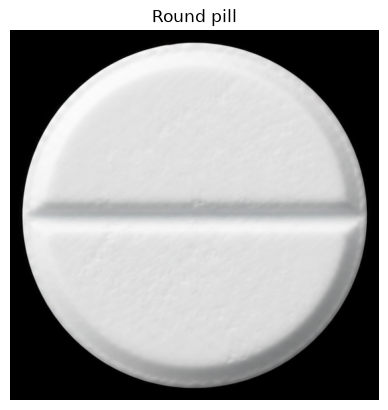

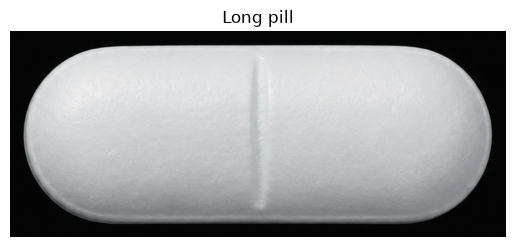

In [8]:
round = cv2.imread("round_pill.png")
long = cv2.imread("long_pill.png")
show_image(round, "Round pill")
show_image(long, "Long pill")

In [9]:
# Round pill rotate
(h, w, d) = round.shape
center = (w // 2, h // 2)
for angle in np.arange(0, 360, 15):
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(round, M, (w, h))
    cv2.imshow("Rotated", rotated)
    cv2.waitKey(0)

In [18]:
# Long pill rotate
(h, w, d) = long.shape
center = (w // 2, h // 2)
for angle in np.arange(0, 360, 15):
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(long, M, (w, h))
    cv2.imshow("Rotated", rotated)
    cv2.waitKey(0)

- As you can see, when rotating the long pill, you will eventually encounter an issue where a part of it gets clipped, something that doesn't happen with the round pill. Let's find a way to fix this.

# 2. Correct rotation

In [21]:
def correct_rotation(image, angle):
    # Take cor of the img
    # Rotate along the center of the img
    (h, w) = image.shape[:2]
    (cX, cY) = (w // 2, h // 2)

    # Get the sin, cos from rotation matrix
    M = cv2.getRotationMatrix2D((cX, cY), angle, 1.0)
    cos = np.abs(M[0, 0])
    sin = np.abs(M[0, 1])

    # Calculate the new h and w (draw the rectangle to understand)
    nw = int((h * sin) + (w * cos))
    nh = int((h * cos) + (w * sin))

    # Shift the shift part from rotation matrix
    M[0, 2] += (nw / 2) - cX
    M[1, 2] += (nh / 2) - cY


    return cv2.warpAffine(image, M, (nw, nh))


In [ ]:
(h, w, d) = round.shape
center = (w // 2, h // 2)
for angle in np.arange(0, 360, 15):
    rotated = correct_rotation(round, angle)
    cv2.imshow("Rotated", rotated)
    cv2.waitKey(0)

In [20]:
(h, w, d) = long.shape
center = (w // 2, h // 2)
for angle in np.arange(0, 360, 15):
    rotated = correct_rotation(long, angle)
    cv2.imshow("Rotated", rotated)
    cv2.waitKey(0)
